## Lab 2 - Task 1: CNN on mel-spectrograms (Keras) — versión Colab

**Antes de empezar:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*, y ejecuta las celdas **en orden**.

- Split 80/20 por canción (el mismo test que en Task 2 y Lab 1)
- Carga de los espectrogramas (recortados, RGB)
- Exploración de configuraciones con una validación sacada solo del 80%
- Reentrenar la mejor sobre todo el train y evaluar **una sola vez** en el 20% de test

Si Colab se desconecta, vuelve a ejecutar desde el principio: los experimentos ya hechos se saltan solos (están en `task1_experiments.csv`, en Drive).

### 0. Drive y datos

In [4]:
from google.colab import drive
drive.mount("/content/drive")

import os, shutil
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")
PROJECT = Path("/content/drive/MyDrive/MSC/music-genre-classification-2")       # si ya sabes la ruta, ponla aquí: Path("/content/drive/MyDrive/.../music-genre-classification-2")

def find_dir(root, name, max_depth=6):
    root = Path(root)
    for dirpath, dirnames, _ in os.walk(root, followlinks=True):
        if name in dirnames:
            return Path(dirpath) / name
        depth = len(Path(dirpath).relative_to(root).parts)
        dirnames[:] = [] if depth >= max_depth else [d for d in dirnames if not d.startswith(".")]
    return None

if PROJECT is None:
    PROJECT = find_dir(DRIVE_ROOT, "music-genre-classification-2")
assert PROJECT is not None, "No encuentro 'music-genre-classification-2' en tu Drive (¿cuenta correcta montada?)"
print("Proyecto:", PROJECT)

SRC_IMAGES   = PROJECT / "data" / "images_original"
LOCAL_IMAGES = Path("/content/data/images_original")      # copia local (mucho más rápida que leer de Drive)
RESULTS_DIR  = PROJECT / "results_task1"                  # todo lo que se guarda va a Drive
RESULTS_DIR.mkdir(exist_ok=True)
assert SRC_IMAGES.exists(), f"No existe {SRC_IMAGES}"

n_local = len(list(LOCAL_IMAGES.glob("*/*.png"))) if LOCAL_IMAGES.exists() else 0
if n_local < 900:
    print("Copiando espectrogramas a /content/data ...")
    shutil.copytree(SRC_IMAGES, LOCAL_IMAGES, dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns(".DS_Store", "._*"))
print("PNGs locales:", len(list(LOCAL_IMAGES.glob("*/*.png"))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proyecto: /content/drive/MyDrive/MSC/music-genre-classification-2
PNGs locales: 999


### 1. Imports y configuración

In [5]:
import os, re, json, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_DIR = LOCAL_IMAGES
SEED = 42

def set_seed(s):
    random.seed(s); np.random.seed(s); keras.utils.set_random_seed(s)   # python + numpy + tensorflow
set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TF", tf.__version__, "| GPUs:", gpus)
if not gpus:
    print("AVISO: sin GPU. Funciona, pero será lento (Entorno de ejecución → Cambiar tipo de entorno → T4 GPU).")

TF 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 2. Tabla de canciones

In [6]:
pat  = re.compile(r'^([a-z]+)(\d{5})\.png$')          # e.g. blues00000.png
rows = []
for gdir in sorted(p for p in IMG_DIR.iterdir() if p.is_dir()):
    for f in sorted(gdir.glob('*.png')):
        m = pat.match(f.name)
        if m:
            rows.append(dict(song=f'{m.group(1)}.{m.group(2)}', genre=m.group(1), path=str(f)))

songs = pd.DataFrame(rows)
GENRES = sorted(songs.genre.unique())                 # alfabético = igual que LabelEncoder en Lab 1
songs['label'] = songs.genre.map({g: i for i, g in enumerate(GENRES)})
print(len(songs), 'songs'); print(songs.genre.value_counts().to_string())

999 songs
genre
blues        100
classical    100
country      100
disco        100
hiphop       100
metal        100
reggae       100
pop          100
rock         100
jazz          99


(432, 288) RGBA


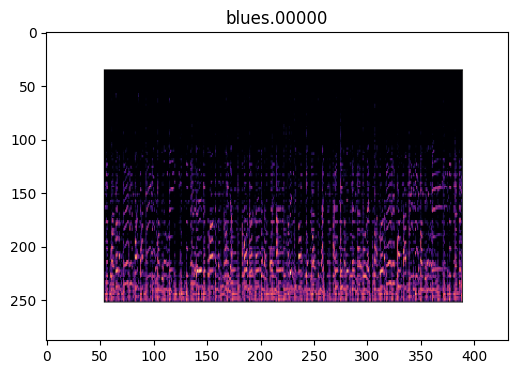

In [7]:
im = Image.open(songs.path[0]); print(im.size, im.mode)
plt.figure(figsize=(6, 4)); plt.imshow(im); plt.title(songs.song[0]); plt.show()

Se ve que las imágenes tienen márgenes (figura de matplotlib con marco blanco y ejes), así que hay que recortarlos. Además son RGBA, así que se convierten a RGB.

El espectrograma real ocupa aproximadamente x ∈ [55, 388] e y ∈ [37, 251] píxeles. El eje horizontal es tiempo (30 s) y el vertical es frecuencia mel (graves abajo).

### 3. Split 80/20 (por canción, estratificado por género)

In [8]:
tr, te = train_test_split(songs.song, test_size=0.2, stratify=songs.genre, random_state=SEED)
split = dict(train=sorted(tr), test=sorted(te))

# Unificar con Task 2: si existe su split, el test tiene que ser EXACTAMENTE el mismo
TASK2_SPLIT = PROJECT / "split_seed42.json"
if TASK2_SPLIT.exists():
    s2 = json.load(open(TASK2_SPLIT))
    def to_id(p):                                   # '.../blues/blues00000.png' -> 'blues.00000'
        p = Path(p); g = p.parent.name
        return f"{g}.{p.stem[len(g):]}"
    te2 = sorted(to_id(p) for p in s2["test"])
    assert set(te2) <= set(songs.song), "El split de Task 2 contiene canciones que no están en images_original"
    same = te2 == split["test"]
    print("Test idéntico al de Task 2:", same)
    if not same:
        print("-> uso el test de Task 2, para que todos los modelos se evalúen en las mismas canciones")
        te_set = set(te2)
        split = dict(train=sorted(s for s in songs.song if s not in te_set), test=te2)
else:
    print("No hay split de Task 2 en Drive; uso el de train_test_split (seed 42).")

# validación interna, sacada SOLO de las canciones de train (para elegir configuración)
tr_songs = songs[songs.song.isin(split['train'])]
sub_tr, sub_va = train_test_split(tr_songs.song, test_size=0.2, stratify=tr_songs.genre, random_state=SEED)

idx_of = lambda names: songs.index[songs.song.isin(set(names))].to_numpy()
IDX_TRAIN, IDX_TEST = idx_of(split['train']), idx_of(split['test'])
IDX_SUB_TR, IDX_VAL = idx_of(sub_tr), idx_of(sub_va)
print(len(IDX_TRAIN), len(IDX_TEST), '| inner:', len(IDX_SUB_TR), len(IDX_VAL))
assert not set(IDX_TRAIN) & set(IDX_TEST)
assert not set(IDX_SUB_TR) & set(IDX_VAL) and set(IDX_SUB_TR) | set(IDX_VAL) == set(IDX_TRAIN)

# IDs tipo 'blues.00000' (mismo formato que Preprocessing del Lab 1: test_groups=split['test'])
json.dump(split, open(RESULTS_DIR / "split_ids.json", "w"), indent=1)

Test idéntico al de Task 2: True
799 200 | inner: 639 160


### 4. Recortar, reescalar y cargar los espectrogramas en memoria (uint8, channels-last)

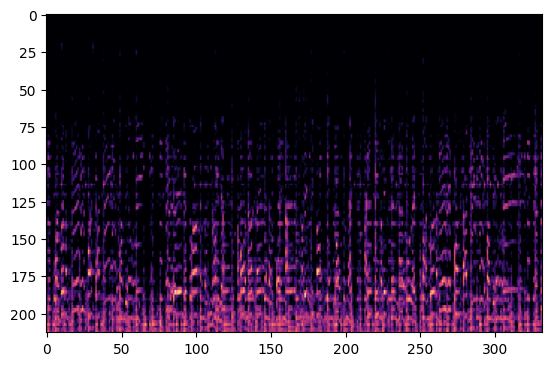

(999, 128, 192, 3) 73.654272 MB


In [9]:
IMG_H, IMG_W = 128, 192        # alto (frecuencia) x ancho (tiempo)
CROP = (55, 37, 387, 250)      # (left, top, right, bottom) en píxeles de la imagen original

def load_img(p):
    im = Image.open(p).convert('RGB').crop(CROP)                      # RGBA -> RGB, quita márgenes
    return np.asarray(im.resize((IMG_W, IMG_H), Image.BILINEAR))      # H,W,3 uint8

# comprobación visual: no debe quedar nada blanco ni marco negro
plt.imshow(Image.open(songs.path[0]).convert('RGB').crop(CROP)); plt.show()

X_all = np.stack([load_img(p) for p in songs.path])                   # N,H,W,3 uint8
y_all = songs.label.to_numpy()
print(X_all.shape, X_all.nbytes / 1e6, 'MB')

# estadísticas de normalización solo con TRAIN
_tr  = X_all[IDX_TRAIN].astype('float32') / 255.
MEAN = _tr.mean((0, 1, 2)); STD = _tr.std((0, 1, 2)); del _tr

### 5. Pipeline de datos (tf.data) con máscaras tipo SpecAugment

In [10]:
def spec_mask(x, y, fmask=16, tmask=24):
    f  = tf.random.uniform([], 0, fmask + 1, tf.int32); f0 = tf.random.uniform([], 0, IMG_H - f + 1, tf.int32)
    t  = tf.random.uniform([], 0, tmask + 1, tf.int32); t0 = tf.random.uniform([], 0, IMG_W - t + 1, tf.int32)
    rows, cols = tf.range(IMG_H), tf.range(IMG_W)
    row_m = (rows >= f0) & (rows < f0 + f)                 # banda de frecuencia
    col_m = (cols >= t0) & (cols < t0 + t)                 # banda de tiempo
    mask  = row_m[:, None] | col_m[None, :]                # H,W
    return tf.where(mask[:, :, None], 0.0, x), y           # 0 = media tras normalizar

def make_ds(idx, augment=False, bs=32, shuffle=False):
    x = (X_all[idx].astype('float32') / 255. - MEAN) / STD
    ds = tf.data.Dataset.from_tensor_slices((x, y_all[idx]))
    if shuffle: ds = ds.shuffle(len(idx), seed=SEED)
    if augment: ds = ds.map(spec_mask, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(tf.data.AUTOTUNE)

# Cambiar el tamaño de entrada (recarga las imágenes con otro tamaño y recalcula MEAN/STD)
SIZE_CACHE = {(IMG_H, IMG_W): (X_all, MEAN, STD)}

def set_input_size(h, w):
    global X_all, MEAN, STD, IMG_H, IMG_W
    if (h, w) not in SIZE_CACHE:
        def _load(p): return np.asarray(Image.open(p).convert('RGB').crop(CROP).resize((w, h), Image.BILINEAR))
        X = np.stack([_load(p) for p in songs.path])
        t = X[IDX_TRAIN].astype('float32') / 255.
        SIZE_CACHE[(h, w)] = (X, t.mean((0, 1, 2)), t.std((0, 1, 2)))
    X_all, MEAN, STD = SIZE_CACHE[(h, w)]
    IMG_H, IMG_W = h, w

### 6. Modelo: CNN configurable

In [11]:
def SimpleCNN(filters=(16, 32, 64), kernel=(3, 3), dropout=0.3, n_classes=10, input_shape=None):
    input_shape = input_shape or (IMG_H, IMG_W, 3)
    inp = keras.Input(shape=input_shape)
    x = inp
    for f in filters:
        x = layers.Conv2D(f, kernel, padding='same')(x)    # kernel = (alto=frecuencia, ancho=tiempo)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(n_classes)(x))    # logits

# solo parámetros entrenables
n_params = lambda m: int(sum(np.prod(tuple(w.shape)) for w in m.trainable_weights))
print(n_params(SimpleCNN()))

24458


### 7. Entrenamiento y predicción (definidos ANTES de usarlos)

In [12]:
def predict_logits(model, idx, bs=128):
    return model.predict(make_ds(idx, bs=bs), verbose=0)

def predict(model, idx, bs=128):
    return predict_logits(model, idx, bs).argmax(1)

def train_model(model, tr_idx, va_idx=None, epochs=40, lr=1e-3, wd=1e-4, bs=32,
                augment=True, patience=10, seed=SEED, verbose=0, stop_epochs=None):
    """`epochs` fija la longitud del schedule cosine; `stop_epochs` (opcional) corta el entrenamiento antes
    sin cambiar el schedule (se usa para reentrenar en el modelo final con la misma dinámica que en la búsqueda)."""
    set_seed(seed)
    steps = int(np.ceil(len(tr_idx) / bs)) * epochs
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=keras.optimizers.schedules.CosineDecay(lr, steps), weight_decay=wd),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy'])
    cbs = []
    if va_idx is not None:
        cbs.append(keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max',
                                                 patience=patience, restore_best_weights=True))
    n_ep = stop_epochs or epochs
    t0 = time.time()
    h = model.fit(make_ds(tr_idx, augment, bs, shuffle=True),
                  validation_data=make_ds(va_idx) if va_idx is not None else None,
                  epochs=n_ep, callbacks=cbs, verbose=verbose, shuffle=False)   # el dataset ya se baraja en make_ds
    hist = pd.DataFrame(h.history); hist.insert(0, 'epoch', range(1, len(hist) + 1))
    if va_idx is not None:
        best_val, best_epoch = float(hist.val_accuracy.max()), int(hist.val_accuracy.idxmax()) + 1
    else:
        best_val, best_epoch = None, n_ep
    return dict(model=model, history=hist, best_val=best_val, best_epoch=best_epoch,
                train_time=time.time() - t0, params=n_params(model))

### 8. Exploración de configuraciones

Se hace en dos etapas, todo registrado en el mismo CSV (en Drive):

1. **Profundidad / filtros** (6 configuraciones).
2. **Un factor cada vez** (dropout, augmentation, lr, kernel, tamaño de entrada) sobre la **mejor configuración de profundidad** de la etapa 1.

Todo se decide con la validación interna (160 canciones); el test no se toca. Con 160 canciones, una canción son 0,6 puntos: diferencias de 1-2 puntos pueden ser ruido.

In [13]:
RESULTS_CSV = RESULTS_DIR / 'task1_experiments.csv'

BASE0 = dict(filters=(32, 64, 128), kernel=(3, 3), dropout=0.3, augment=True, lr=1e-3, size=(128, 192))

DEPTH_EXPERIMENTS = {
    '2conv_16-32':             dict(filters=(16, 32)),
    '3conv_16-32-64':          dict(filters=(16, 32, 64)),
    '3conv_32-64-128':         dict(filters=(32, 64, 128)),
    '4conv_16-32-64-128':      dict(filters=(16, 32, 64, 128)),
    '4conv_32-64-128-256':     dict(filters=(32, 64, 128, 256)),
    '5conv_32-64-128-256-256': dict(filters=(32, 64, 128, 256, 256)),
}
FACTOR_EXPERIMENTS = {
    'dropout_0.0':     dict(dropout=0.0),
    'dropout_0.5':     dict(dropout=0.5),
    'no_augment':      dict(augment=False),
    'lr_3e-4':         dict(lr=3e-4),
    'lr_3e-3':         dict(lr=3e-3),
    'kernel_5x5':      dict(kernel=(5, 5)),
    'kernel_7x3_freq': dict(kernel=(7, 3)),   # alto en frecuencia
    'kernel_3x7_time': dict(kernel=(3, 7)),   # ancho en tiempo
    'size_64x96':      dict(size=(64, 96)),
    'size_192x288':    dict(size=(192, 288)),   # el más lento: va el último
}

def fmt(cfg):
    return dict(filters='-'.join(map(str, cfg['filters'])), kernel='x'.join(map(str, cfg['kernel'])),
                dropout=cfg['dropout'], augment=cfg['augment'], lr=cfg['lr'],
                img_h=cfg['size'][0], img_w=cfg['size'][1])

def run_experiments(exps, base, group):
    done = set(pd.read_csv(RESULTS_CSV).name) if RESULTS_CSV.exists() else set()   # reanuda si se corta
    for name, over in exps.items():
        if name in done:
            print('skip (ya hecho):', name); continue
        cfg = {**base, **over}
        print('=====', name, fmt(cfg))
        set_input_size(*cfg['size'])
        keras.backend.clear_session()
        out = train_model(SimpleCNN(filters=cfg['filters'], kernel=cfg['kernel'], dropout=cfg['dropout']),
                          IDX_SUB_TR, IDX_VAL, lr=cfg['lr'], augment=cfg['augment'])
        row = dict(name=name, group=group, **fmt(cfg), depth=len(cfg['filters']), params=out['params'],
                   best_val_acc=out['best_val'], best_epoch=out['best_epoch'], train_time_s=out['train_time'])
        pd.DataFrame([row]).to_csv(RESULTS_CSV, mode='a', header=not RESULTS_CSV.exists(), index=False)   # guarda ya
        print({k: row[k] for k in ('best_val_acc', 'best_epoch', 'params', 'train_time_s')})
    set_input_size(*BASE0['size'])

# --- Etapa 1: profundidad / filtros ---
run_experiments(DEPTH_EXPERIMENTS, BASE0, 'depth')
depth_df = pd.read_csv(RESULTS_CSV).query("group == 'depth'").sort_values('best_val_acc', ascending=False)
print(depth_df[['name', 'params', 'best_val_acc', 'best_epoch', 'train_time_s']].to_string(index=False))

# --- Etapa 2: un factor cada vez sobre la mejor profundidad ---
BASE = {**BASE0, 'filters': tuple(map(int, depth_df.iloc[0].filters.split('-')))}
print('\nBASE para la etapa 2:', BASE)
run_experiments(FACTOR_EXPERIMENTS, BASE, 'factor')

===== 2conv_16-32 {'filters': '16-32', 'kernel': '3x3', 'dropout': 0.3, 'augment': True, 'lr': 0.001, 'img_h': 128, 'img_w': 192}
{'best_val_acc': 0.4625000059604645, 'best_epoch': 24, 'params': 5514, 'train_time_s': 37.40745425224304}
===== 3conv_16-32-64 {'filters': '16-32-64', 'kernel': '3x3', 'dropout': 0.3, 'augment': True, 'lr': 0.001, 'img_h': 128, 'img_w': 192}
{'best_val_acc': 0.59375, 'best_epoch': 38, 'params': 24458, 'train_time_s': 39.058305501937866}
===== 3conv_32-64-128 {'filters': '32-64-128', 'kernel': '3x3', 'dropout': 0.3, 'augment': True, 'lr': 0.001, 'img_h': 128, 'img_w': 192}
{'best_val_acc': 0.6875, 'best_epoch': 37, 'params': 94986, 'train_time_s': 55.105493783950806}
===== 4conv_16-32-64-128 {'filters': '16-32-64-128', 'kernel': '3x3', 'dropout': 0.3, 'augment': True, 'lr': 0.001, 'img_h': 128, 'img_w': 192}
{'best_val_acc': 0.7437499761581421, 'best_epoch': 40, 'params': 99210, 'train_time_s': 38.43083429336548}
===== 4conv_32-64-128-256 {'filters': '32-64-1

In [14]:
res_df = pd.read_csv(RESULTS_CSV).sort_values('best_val_acc', ascending=False).reset_index(drop=True)
res_df

,name,group,filters,kernel,dropout,augment,lr,img_h,img_w,depth,params,best_val_acc,best_epoch,train_time_s
0,dropout_0.0,factor,32-64-128-256,3x3,0.0,True,0.0010,128,192,4,391946,0.77500,39,50.610326
1,4conv_32-64-128-256,depth,32-64-128-256,3x3,0.3,True,0.0010,128,192,4,391946,0.76250,40,57.018652
2,no_augment,factor,32-64-128-256,3x3,0.3,False,0.0010,128,192,4,391946,0.75625,37,48.204970
3,size_192x288,factor,32-64-128-256,3x3,0.3,True,0.0010,192,288,4,391946,0.75000,38,113.605839
4,4conv_16-32-64-128,depth,16-32-64-128,3x3,0.3,True,0.0010,128,192,4,99210,0.74375,40,38.430834
5,kernel_5x5,factor,32-64-128-256,5x5,0.3,True,0.0010,128,192,4,1081610,0.73750,40,74.282763
6,size_64x96,factor,32-64-128-256,3x3,0.3,True,0.0010,64,96,4,391946,0.72500,38,29.899014
7,lr_3e-4,factor,32-64-128-256,3x3,0.3,True,0.0003,128,192,4,391946,0.71875,36,52.891421
8,lr_3e-3,factor,32-64-128-256,3x3,0.3,True,0.0030,128,192,4,391946,0.71250,40,52.600560
9,3conv_32-64-128,depth,32-64-128,3x3,0.3,True,0.0010,128,192,3,94986,0.68750,37,55.105494


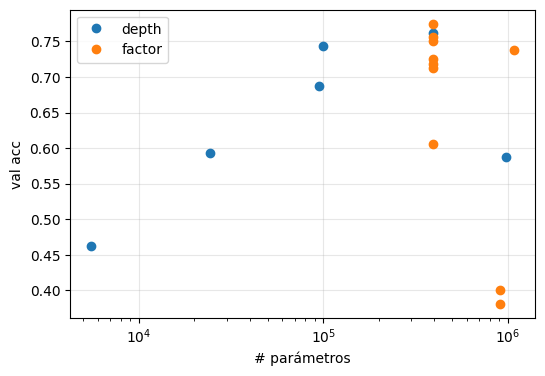

mejor en validación: dropout_0.0


In [15]:
# Accuracy de validación vs nº de parámetros (profundidad y resto de factores por separado)
plt.figure(figsize=(6, 4))
for g, c in (('depth', 'tab:blue'), ('factor', 'tab:orange')):
    d = res_df[res_df.group == g]
    plt.semilogx(d.params, d.best_val_acc, 'o', color=c, label=g)
plt.xlabel('# parámetros'); plt.ylabel('val acc'); plt.grid(alpha=.3); plt.legend(); plt.show()
print('mejor en validación:', res_df.iloc[0]['name'])

### 9. Modelo final: reentrenar con todo el 80% y evaluar una sola vez en el 20% de test

mejor en validación: dropout_0.0
{'filters': (32, 64, 128, 256), 'kernel': (3, 3), 'dropout': 0.0, 'augment': True, 'lr': 0.001, 'size': (128, 192)} | epochs: 39
TEST acc = 0.8000 | params = 391,946 | train 56s | inferencia 8.8 ms/canción


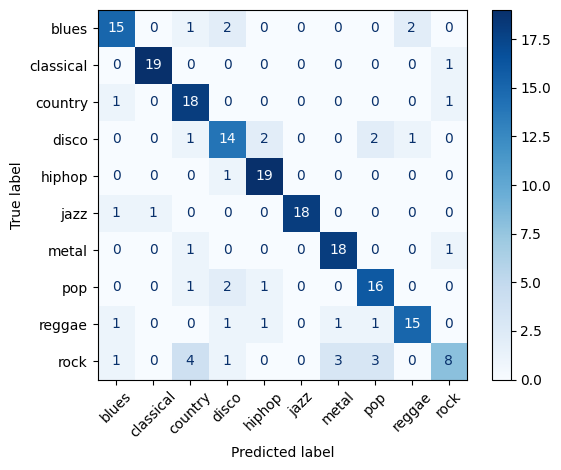

In [16]:
best = res_df.iloc[0]; best_name = best['name']; print('mejor en validación:', best_name)
BEST_CFG = dict(filters=tuple(map(int, best.filters.split('-'))), kernel=tuple(map(int, best.kernel.split('x'))),
                dropout=float(best.dropout), augment=bool(best.augment), lr=float(best.lr),
                size=(int(best.img_h), int(best.img_w)))
BEST_EPOCH = int(best.best_epoch)
print(BEST_CFG, '| epochs:', BEST_EPOCH)

set_input_size(*BEST_CFG['size'])
keras.backend.clear_session()
# mismo schedule (40 epochs) que en la búsqueda, cortado en BEST_EPOCH
final = train_model(SimpleCNN(filters=BEST_CFG['filters'], kernel=BEST_CFG['kernel'], dropout=BEST_CFG['dropout']),
                    IDX_TRAIN, None, epochs=40, stop_epochs=BEST_EPOCH,
                    lr=BEST_CFG['lr'], augment=BEST_CFG['augment'])
model = final['model']

# --- Test (una sola vez) ---
ds_test = make_ds(IDX_TEST, bs=128)
model.predict(ds_test.take(1), verbose=0)                 # warm-up (compilación), sin cronometrar
t0 = time.time(); logits = model.predict(ds_test, verbose=0)
infer_s = time.time() - t0
pred = logits.argmax(1); y_test = y_all[IDX_TEST]; acc = (pred == y_test).mean()
print(f'TEST acc = {acc:.4f} | params = {final["params"]:,} | train {final["train_time"]:.0f}s | '
      f'inferencia {infer_s/len(IDX_TEST)*1000:.1f} ms/canción')

# --- Guardar todo lo necesario para las research questions (solapamiento de errores, ensembles, tabla de coste) ---
test_songs = songs.song.to_numpy()[IDX_TEST]
probs = tf.nn.softmax(logits).numpy()
pd.DataFrame(dict(song=test_songs, y_true=y_test, y_pred=pred)).to_csv(RESULTS_DIR / 'task1_test_predictions.csv', index=False)
np.save(RESULTS_DIR / 'task1_test_probs.npy', probs)                      # mismo orden que task1_test_predictions.csv
pd.DataFrame([dict(model='scratch_cnn', cfg=best_name, test_acc=acc, params=final['params'],
                   train_time_s=final['train_time'], infer_ms_per_song=infer_s / len(IDX_TEST) * 1000)]
             ).to_csv(RESULTS_DIR / 'task1_final.csv', index=False)
model.save(RESULTS_DIR / 'task1_best_cnn.keras')

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=GENRES).plot(xticks_rotation=45, cmap='Blues')
plt.show()